<div style="background-color:rgb(100, 110, 220); padding:10px;">

## Day 2: Exploratory Data Analysis and Advanced Regression

- **Data Preprocessing**
  - **Exploratory Data Analysis (EDA)**
    - Data visualization (histograms, scatter plots, box plots)
    - Descriptive statistics
    - Identifying patterns 
- **Machine Learning Algorithms**
  - Advanced Regression (Ridge and Lasso Regression)
- **Model Selection and Evaluation**
  - Bias-Variance Tradeoff in Regression
  - Overfitting vs. Underfitting

### Dataset: weatherHistory_train_Val.csv
We use 64% for training, 16% for validation and 20% for a final test. The validation set guides comparison; the test set stays unused until final evaluation.
### libraries: pandas, scikit learn, matplotlib, numpy, and seaborn
</div>

# 1. Data Preprocessing

In [1]:
import pandas as pd
df = pd.read_csv('../Lecture_data/weatherHistory_train_Val.csv')
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Daily Summary
0,2006-08-14 18:00:00.000 +0200,Partly Cloudy,rain,22.477778,22.477778,0.58,10.8192,159.0,11.1251,0.0,Mostly cloudy until night.
1,2006-08-15 10:00:00.000 +0200,Partly Cloudy,rain,21.061111,21.061111,0.73,7.7924,264.0,11.2056,0.0,Partly cloudy until evening.
2,2006-08-17 12:00:00.000 +0200,Clear,rain,28.838889,29.611111,0.51,9.6600,177.0,9.9820,0.0,Partly cloudy until morning.
3,2006-08-18 09:00:00.000 +0200,Clear,rain,24.950000,24.950000,0.69,16.0195,180.0,9.9015,0.0,Partly cloudy starting overnight continuing un...
4,2006-08-22 18:00:00.000 +0200,Partly Cloudy,rain,23.811111,23.811111,0.45,16.0195,290.0,11.2056,0.0,Partly cloudy starting in the morning.


In [2]:
#1. For this example, treat exact duplicate rows as accidental copies.


df.duplicated().sum()
df = df.drop_duplicates()

In [3]:
# dropping unhelpful columns:
# note: you have to do this step on unseen or test dataset as well or Put column dropping/selection inside the pipeline
df.nunique()

Formatted Date              88855
Summary                        27
Precip Type                     2
Temperature (C)              7233
Apparent Temperature (C)     8716
Humidity                       89
Wind Speed (km/h)            2480
Wind Bearing (degrees)        360
Visibility (km)               945
Pressure (millibars)         3629
Daily Summary                 213
dtype: int64

In [4]:
#2. understanding the goal, target and splitting
# Identify the target and create development/test sets.
y = df['Humidity']
X = df.drop(columns=['Humidity', 'Formatted Date', 'Apparent Temperature (C)'], errors='ignore')
from sklearn.model_selection import train_test_split
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.2, random_state=42)
# This gives 64% training, 16% validation and 20% test data.

In [5]:
X_train.dtypes

Summary                    object
Precip Type                object
Temperature (C)           float64
Wind Speed (km/h)         float64
Wind Bearing (degrees)    float64
Visibility (km)           float64
Pressure (millibars)      float64
Daily Summary              object
dtype: object

In [6]:
#2"" categorical and numeric data 
# for now lets Drop non-numeric columns and we will be learning how to handle categorical data in lecture3
import numpy as np
num_cols = X_train.select_dtypes(include=[np.number]).columns
X_train = X_train[num_cols]
X_val = X_val[num_cols]
X_test = X_test[num_cols]

## 1.1 Exploratory Data Analysis (EDA)


###  Descriptive Statistics
Descriptive statistics summarize the central tendency, dispersion, and shape of a dataset’s distribution.

- **Summary Statistics:** Calculate mean, median, standard deviation, and quartiles for each numerical feature.
- **Distribution Analysis:** Analyze skewness and kurtosis to understand the data's distribution characteristics.
- **Close look at each feature like `value_counts()` to have a better decision**

###  Data Visualization
Visualizing the data helps us understand the distribution of features, identify relationships between them, and detect potential outliers.

- **Box Plots:** Useful for identifying the distribution and detecting outliers within numerical features.
- **Histograms:** Useful for understanding the distribution of individual numerical features.
- **Scatter Plots:** Help examine relationships between pairs of numerical features.
- We can use `matplotlib`, `seaborn`, or `pandas` to visualize

In [7]:
#  Summary Statistics
X_train.describe()

,Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars)
count,56819.000000,56861.000000,56859.000000,56842.000000,56867.000000
mean,12.853411,11.084831,189.670043,10.622760,1000.491711
std,9.206214,6.964677,106.513600,4.008216,122.526419
min,-16.111111,0.000000,0.000000,0.000000,0.000000
25%,6.022222,6.134100,120.000000,9.756600,1011.430000
50%,12.716667,10.432800,181.000000,10.255700,1015.800000
75%,19.400000,14.312900,290.000000,14.908600,1019.840000
max,39.905556,54.884900,359.000000,16.100000,1027.900000


In [8]:
#  missing values
X_train.isnull().sum()

Temperature (C)           48
Wind Speed (km/h)          6
Wind Bearing (degrees)     8
Visibility (km)           25
Pressure (millibars)       0
dtype: int64

In [9]:
from sklearn.impute import SimpleImputer

# Imputation for numerical data
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)


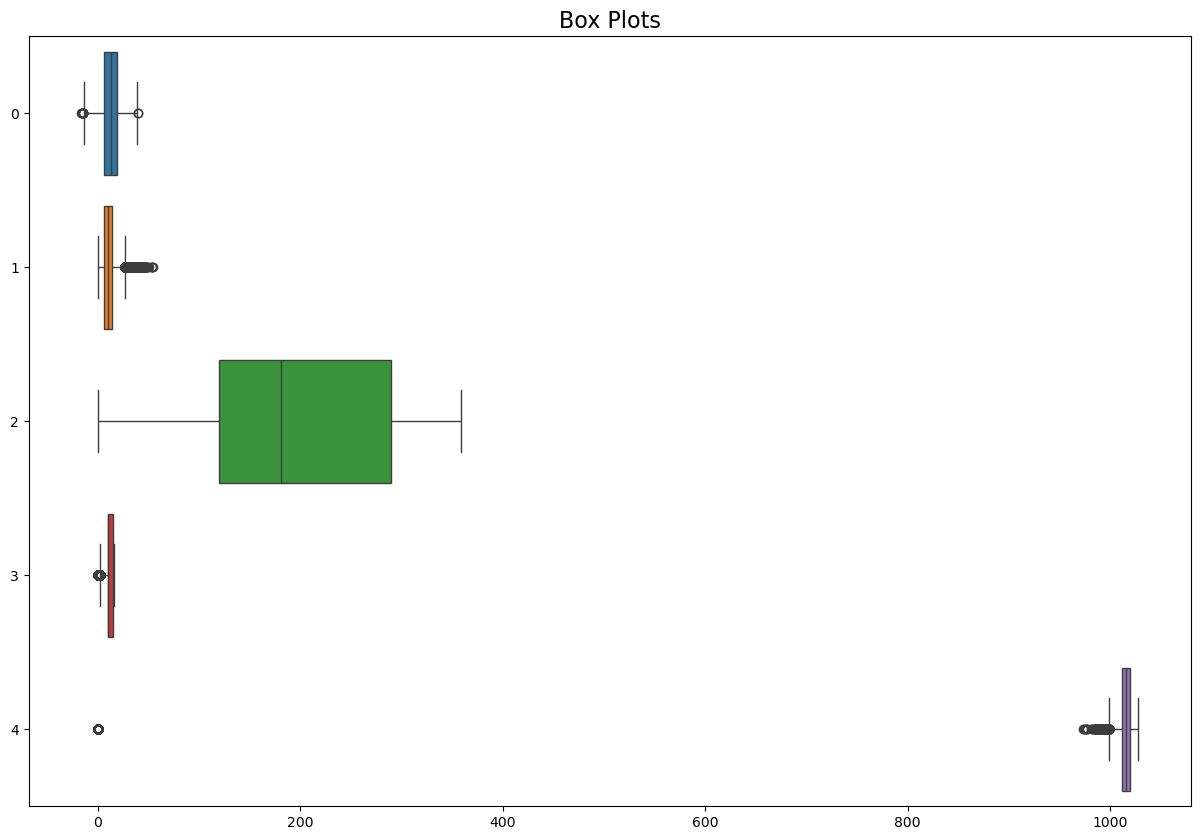

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
#  Box Plots
plt.figure(figsize=(15, 10))
sns.boxplot(data=X_train_imputed, orient='h')
plt.title('Box Plots', fontsize=16)
plt.show()


### Techniques for Outlier Detection
### Techniques for Outlier Detection

**Descriptive statistics:** examine min/max, quartiles, IQR, skewness and kurtosis using training data.

**Visualisations:** inspect box plots, histograms and feature–target scatter plots. Look at observed values before imputation as well as transformed data.
Tip: Plot before and after imputation to avoid “missingness as outliers.”

**Z-score:** a rule such as `|z| > 3` flags unusual values relative to the mean and standard deviation. It is sensitive to extreme values and can be misleading for heavy-tailed distributions.

**IQR:** values outside `[Q1 - 1.5 × IQR, Q3 + 1.5 × IQR]` are flags for investigation, not proof of an error.

**🚫Leakage rule:**  
Learn statistical thresholds using training data only. Apply the same feature transformation to validation/test data; do not delete difficult held-out cases merely because they are extreme.


### Handling Outliers

- **Correct clear errors:** use a documented domain rule. If a row must be excluded, keep its features and target aligned. Decide eligibility rules before evaluating a model.
- **Retain legitimate extremes:** rare observations may be important for the application.
- **Consider feature capping:** clipping to training-derived bounds changes the data and can discard useful signal. Validate this choice; do not alter evaluation targets to improve a score.
- **Consider transformations:** log and Box–Cox require positive values; square root requires nonnegative values; `log1p` requires values greater than -1. Yeo–Johnson can handle zero and negative values. Adding a small constant is not a general remedy for invalid inputs.
- **Consider a different loss:** Huber or absolute-error losses can reduce sensitivity to large response residuals. RobustScaler uses robust scale estimates, but does not by itself make regression robust to all outliers.

**In this demonstration:** we illustrate IQR capping of numerical features. Bounds come from the training set and are applied unchanged to validation data. This is a modelling choice, not an automatic recommendation for every feature.

During a learning curve, recompute imputation values, caps and scaling using only the current training subset.


**🚫Common pitfalls to call out:**

- Setting caps using all data (leakage).
- Dropping rows in X_train but not dropping the same rows in y_train.
- Using z-scores on heavily skewed features without transforming first.
- Applying transforms (e.g., log) before fixing zeros/negatives.

In [11]:
X_train_imputed= pd.DataFrame(X_train_imputed, columns=X_train.columns, index=X_train.index)
X_val_imputed = pd.DataFrame(X_val_imputed, columns=X_val.columns, index=X_val.index)


<Axes: >

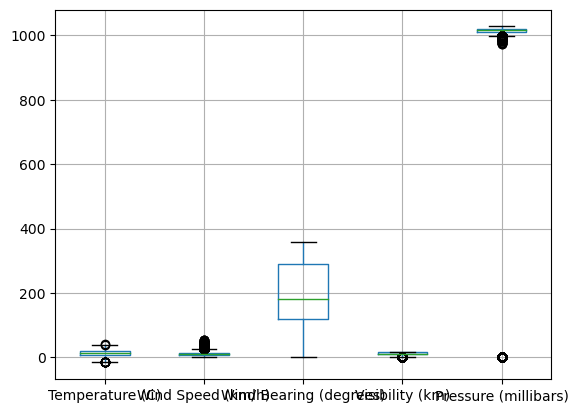

In [12]:
X_train_imputed.boxplot()

<div style="background-color:rgb(160, 130, 200); padding:10px;">
    
**Based on the EDA steps above, we can now make informed decisions about how to handle outliers.
you will handle outlier in the first excercise**
</div>



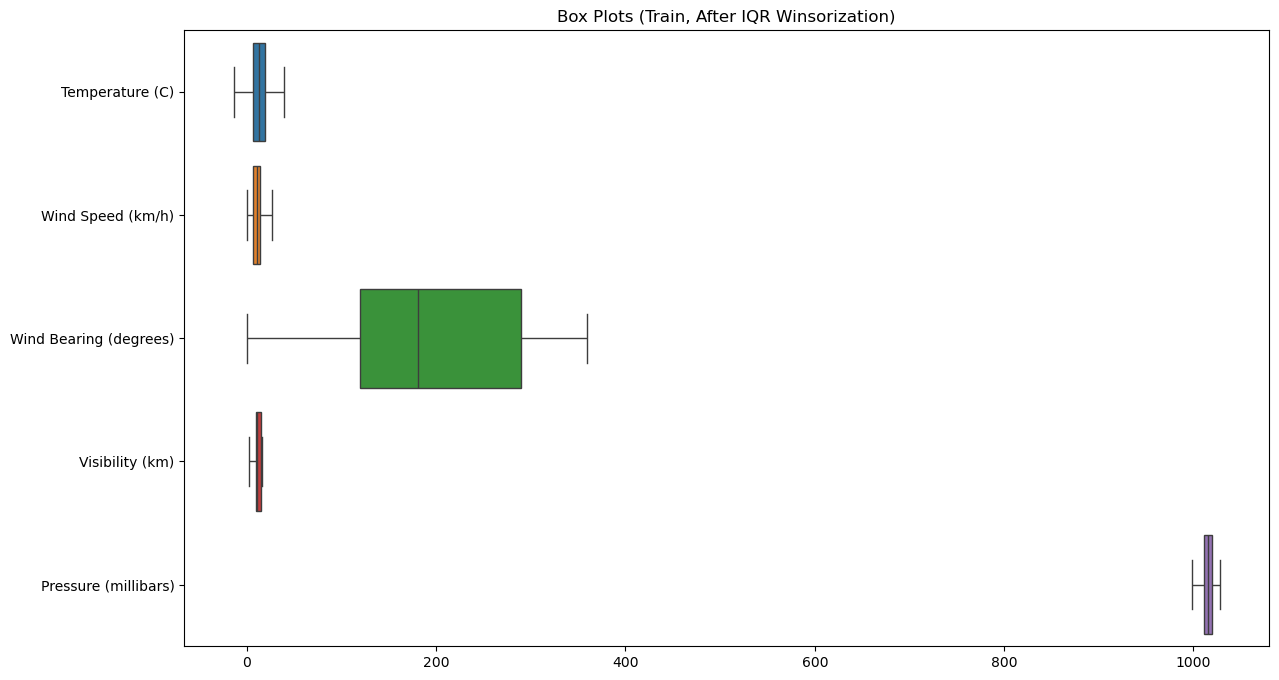

In [13]:
def iqr_caps(frame, whisker=1.5):
    """Return per-column lower/upper caps from IQR, computed on `frame`."""
    q1 = frame.quantile(0.25, numeric_only=True)
    q3 = frame.quantile(0.75, numeric_only=True)
    iqr = q3 - q1
    lower = q1 - whisker * iqr
    upper = q3 + whisker * iqr
    return lower, upper

def winsorize(frame, lower, upper):
    """Cap values using provided per-column lower/upper Series."""
    capped = frame.copy()
    for c in frame.columns:
        if np.issubdtype(frame[c].dtype, np.number):
            if c in lower.index:
                capped[c] = np.clip(frame[c], lower[c], upper[c])
    return capped

# Compute caps on TRAIN ONLY
lower_cap, upper_cap = iqr_caps(X_train_imputed, whisker=1.5)

# Apply the training bounds to train and validation features
X_train_wins = winsorize(X_train_imputed, lower_cap, upper_cap)
X_val_wins  = winsorize(X_val_imputed,  lower_cap, upper_cap)

# Quick visual check
plt.figure(figsize=(14, 8))
sns.boxplot(data=X_train_wins, orient='h')
plt.title('Box Plots (Train, After IQR Winsorization)')
plt.show()

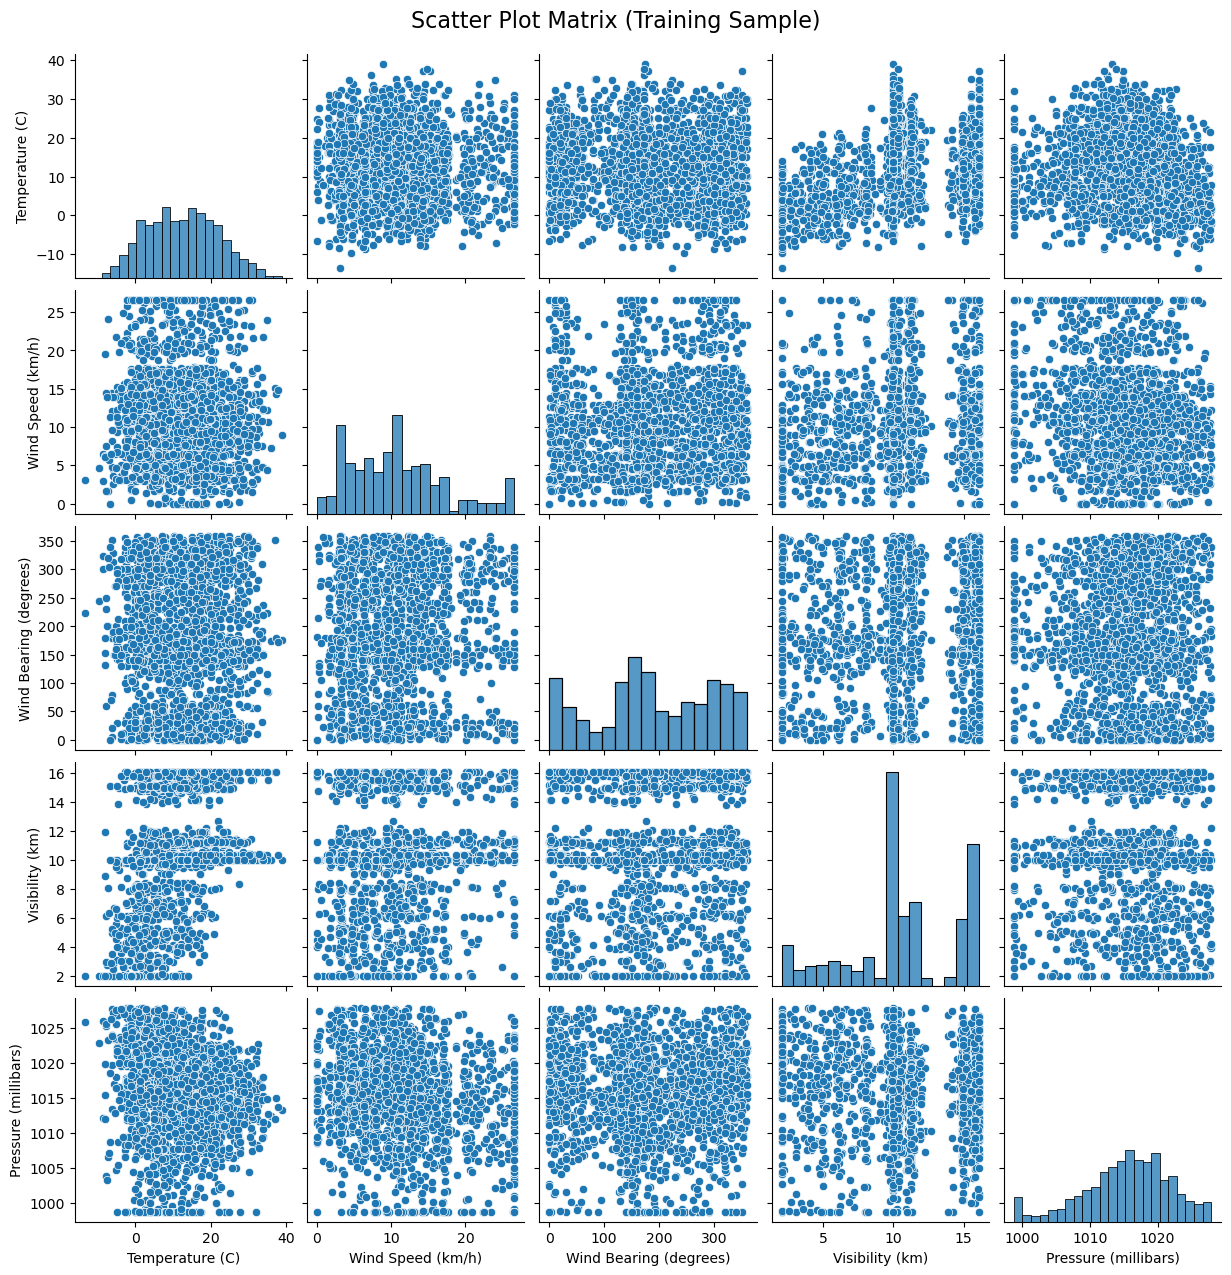

In [14]:
# Sample training rows for readability; statistics use all training rows.
plot_sample = X_train_wins.sample(n=min(2000, len(X_train_wins)), random_state=42)
sns.pairplot(plot_sample)
plt.suptitle('Scatter Plot Matrix (Training Sample)', y=1.02, fontsize=16)
plt.show()

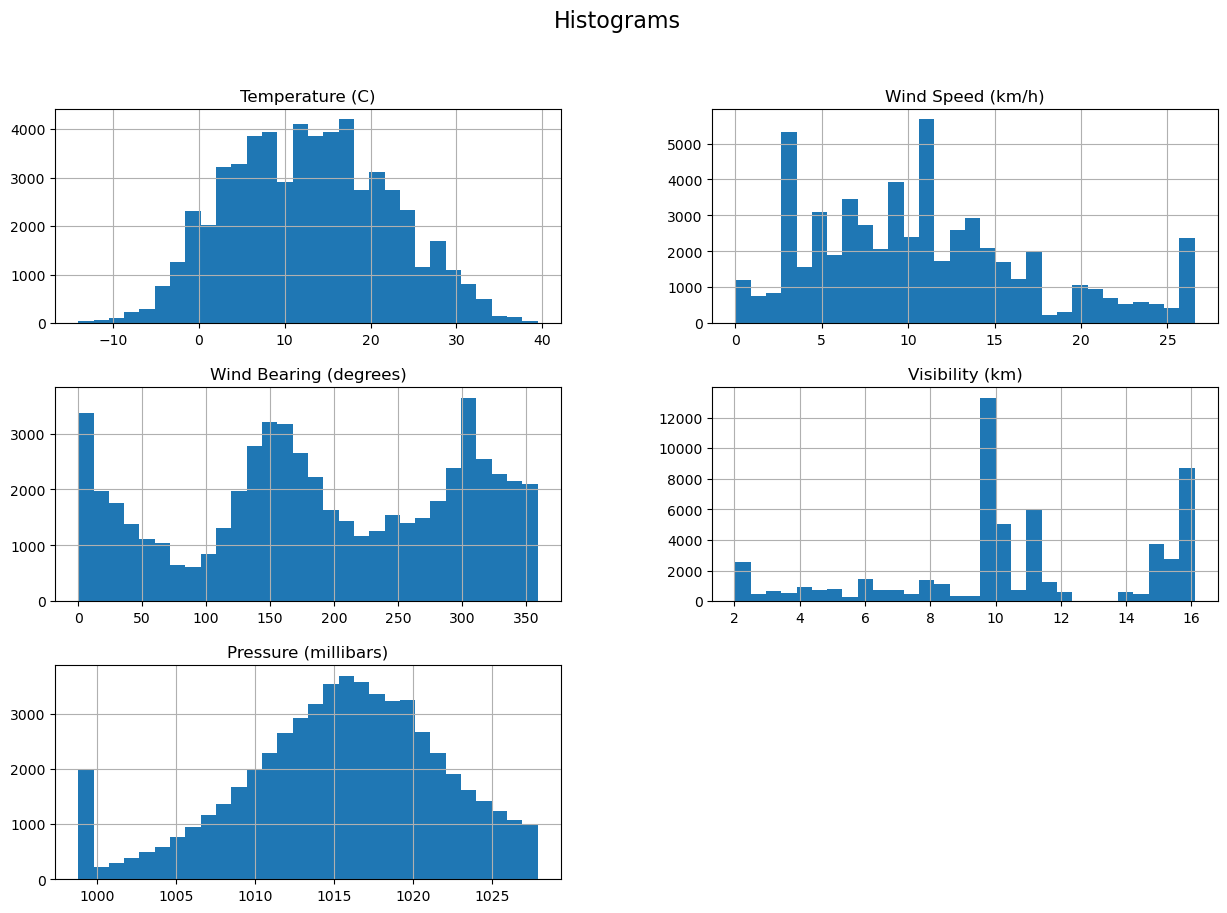

In [15]:
#  Histograms
X_train_wins.hist(bins=30, figsize=(15, 10))
plt.suptitle('Histograms', fontsize=16)
plt.show()

<div style="background-color:rgb(160, 130, 200); padding:10px;">

**Use EDA to understand units, ranges and extreme values. Choose scaling for the model and its distance or penalty calculations; histogram shape alone does not determine the scaler. StandardScaler and MinMaxScaler do not remove skewness. We use StandardScaler here to make numerical feature scales comparable before regularisation.**

</div>

In [16]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_wins)
X_val_scaled = scaler.transform(X_val_wins)

# 2. Machine Advanced Regression Models with a Focus on Regularization

<div style="background-color:rgba(60, 179, 113, 0.3); padding:10px;">

## 1. Introduction to Regularization

Regularisation adds a coefficient penalty to a data-fit loss. It can improve generalisation by restricting the fitted model, but too much penalty can cause underfitting.

Write predictions as
$$\hat y_i=b+\sum_{j=1}^{p}X_{ij}w_j.$$
Here $m$ is the number of training observations. The intercept $b$ is **not penalised**. Scale features deliberately because coefficient penalties depend on feature units.

## 2. Ridge Regression (L2 Regularization)

### Cost Function
To match `sklearn.linear_model.Ridge`, use:
$$J_{\mathrm{Ridge}}(b,w)=\sum_{i=1}^{m}(y_i-b-X_iw)^2+\alpha\sum_{j=1}^{p}w_j^2.$$

Ridge penalises the squared coefficient norm. It generally shrinks coefficients without enforcing sparsity. It can stabilise coefficients when predictors are correlated; it does not remove their correlation.

### Optimization
For centred features $X_c$ and centred response $y_c$:
$$w=(X_c^TX_c+\alpha I)^{-1}X_c^Ty_c,\qquad b=\bar y-\bar Xw.$$
For $\alpha>0$, the penalised matrix is invertible. At $\alpha=0$, the inverse formula needs full column rank; least-squares solvers can handle rank-deficient designs.

The same coefficient formula applies to a model with **no intercept** using $X,y$ directly. If the intercept is included as a column of ones, its penalty entry must be zero.

## 3. Lasso Regression (L1 Regularization)

### Cost Function
To match `sklearn.linear_model.Lasso`:
$$J_{\mathrm{Lasso}}(b,w)=\frac{1}{2m}\sum_{i=1}^{m}(y_i-b-X_iw)^2+\alpha\sum_{j=1}^{p}|w_j|.$$

The L1 penalty can set coefficients to zero. With highly correlated predictors, the selected allocation may be unstable or non-unique.

### Optimization
The absolute-value penalty is not differentiable at zero. Scikit-learn uses coordinate descent. There is no general inverse-matrix formula analogous to Ridge; special designs have simpler solutions.

## 4. Elastic Net (L1 and L2 Regularization)

### Cost Function
With $r=$ `l1_ratio`, scikit-learn uses:
$$J_{\mathrm{EN}}(b,w)=\frac{1}{2m}\sum_{i=1}^{m}(y_i-b-X_iw)^2
+\alpha r\sum_{j=1}^{p}|w_j|
+\frac{\alpha(1-r)}{2}\sum_{j=1}^{p}w_j^2.$$

The L1 part encourages sparsity; the L2 part can encourage correlated predictors to share coefficient weight. Coordinate descent is used to fit the model.

### Comparing Penalty Strengths
These libraries use different normalisations of the data-fit term. Equal numerical values of `alpha` do **not** mean equal regularisation across Ridge, Lasso and ElasticNet.

If instead you write Ridge as $\mathrm{MSE}+\lambda\lVert w\rVert_2^2$, the corresponding scikit-learn value is $\alpha=m\lambda$. Choose one convention and keep it consistent.

<img src="../imgs/regularization_fit_tradeoff.gif" width="800">


[Reference objectives: Ridge](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.Ridge.html), [Lasso](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.Lasso.html), [ElasticNet](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.ElasticNet.html).

</div>

In [17]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

# Illustrative settings, not equally strong penalties or tuned optima.
models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1, max_iter=10000),
    'Elastic Net': ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
}
validation_rmse = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    val_pred = model.predict(X_val_scaled)
    validation_rmse[name] = np.sqrt(mean_squared_error(y_val, val_pred))
    val_r2 = r2_score(y_val, val_pred)
    print(f'{name}: validation RMSE = {validation_rmse[name]:.4f}, R² = {val_r2:.4f}')

selected_name = min(validation_rmse, key=validation_rmse.get)
print('Selected by validation RMSE:', selected_name)
# Do not inspect the test set yet.

Ridge: validation RMSE = 0.1357, R² = 0.5169
Lasso: validation RMSE = 0.1791, R² = 0.1587
Elastic Net: validation RMSE = 0.1580, R² = 0.3449
Selected by validation RMSE: Ridge


### **Choosing a Model**

Treat these as starting points, then compare using validation data:

- **OLS:** an unregularised baseline. Correlated predictors can make individual coefficients unstable even when predictions remain useful.
- **Ridge:** useful when shrinkage is appropriate, especially with correlated predictors.
- **Lasso:** useful when a sparse coefficient vector is desirable; selected features need careful interpretation when predictors are correlated.
- **Elastic Net:** combines sparsity and L2 shrinkage, with an additional mixing parameter to choose.

A model family is not automatically best for a dataset. The examples compare three fixed settings; model or hyperparameter decisions belong on validation data. Evaluate the selected procedure on the test set only once.


<img src="../imgs/regularization_geometry.gif" width="600">


## 🔧  Hyperparameters (also see FAQ)

### Lasso Regression (Lasso)
- **alpha**: Controls the strength of the L1 regularization. Higher values of alpha increase regularization, pushing coefficients toward zero, and potentially leading to sparse models (with some coefficients being zero).
- **max_iter**: Sets the maximum number of iterations for the optimization. Adjust this if the model does not converge.
- **tol**: The tolerance for stopping criteria. Lower values can lead to a more accurate solution but may require more iterations.
- **selection**: Coordinate descent update order: `cyclic` or `random`.


### Ridge Regression (Ridge)
- **alpha**: Controls the strength of the L2 regularization. Larger alpha values increase the penalty, reducing model complexity by shrinking coefficients.
- **solver**: Specifies the optimization algorithm to use. Common options are "auto", "svd", "cholesky", "lsqr", and "saga". Some solvers work better for larger datasets.
- **tol**: Sets the tolerance for the solver's stopping criteria, useful if convergence issues arise.

### Elastic Net (ElasticNet)
- **alpha**: Controls the combined strength of both L1 and L2 regularization. Larger values increase overall regularization.
- **l1_ratio**: Sets the mix of L1 and L2 penalties. Values range from 0 to 1:
  - **l1_ratio = 1** is equivalent to Lasso (pure L1).
  - **l1_ratio = 0** gives a pure L2 objective, equivalent mathematically to `Ridge(alpha=m * alpha)` for $m$ training observations. Prefer Ridge for this case; the numerical alpha conventions differ.
  - Intermediate values combine both, with higher values placing more weight on L1.
- **max_iter** and **tol**: As with Lasso, these control the optimization process and convergence criteria.
- **selection**: Coordinate descent update order: `cyclic` or `random`.

<img src="../imgs/regularization_coefficient_paths.gif" width="800">


# 3. Model Selection and Evaluation: Bias-Variance Tradeoff, Overfitting vs. Underfitting

## 1. Understanding Overfitting and Underfitting

- **Overfitting:**
  - **Definition:** Overfitting occurs when a model learns the training data too well, capturing noise and outliers in addition to the underlying patterns. This leads to a model that performs well on the training data but poorly on new, unseen data.
  - **Symptoms:** Low training error but high test error.
  - **When It Happens:** Overfitting often occurs when the model is too complex relative to the amount of data available, or when too many features are included without adequate regularization.

- **Underfitting:**
  - **Definition:** Underfitting occurs when a model is too simple to capture the underlying patterns in the data. This results in a model that performs poorly on both the training and test data.
  - **Symptoms:** High training error and high test error.
  - **When It Happens:** Underfitting usually happens when the model is too simple (e.g., linear models applied to non-linear data) or when not enough features are included.

---

## 2. The Bias-Variance Tradeoff


## 1. Prediction Error Decomposition: 
At a fixed feature vector $x$, write a new response as
$$Y=f(x)+\varepsilon,\qquad f(x)=\mathbb{E}[Y\mid X=x].$$
Assume $\mathbb{E}[\varepsilon\mid X=x]=0$, finite variances, and test noise independent of training dataset $D$. Let $\hat f_D(x)$ be the prediction learned from $D$.

Then
$$\mathbb{E}_{D,\varepsilon}[(Y-\hat f_D(x))^2\mid X=x]
=\underbrace{(\mathbb{E}_D[\hat f_D(x)]-f(x))^2}_{\mathrm{Bias}^2}
+\underbrace{\mathbb{E}_D[(\hat f_D(x)-\mathbb{E}_D[\hat f_D(x)])^2]}_{\mathrm{Variance}}
+\underbrace{\mathrm{Var}(\varepsilon\mid X=x)}_{\mathrm{Noise}}.$$

in a simpler shape the expected prediction error for a new data point \( x \) can be expressed as:

$$
\mathbb{E}[(y - \hat{y})^2] = \text{Bias}^2 + \text{Variance} + \text{Irreducible Error}
$$

Where:
- $ y$ is the true output.
- $ \hat{y}$ is the predicted output from the model.
- The irreducible error is the noise inherent in the data.

## 2. Bias
Bias compares the average prediction over repeated training datasets with the **conditional mean** $f(x)$, not with one noisy observed response:
$$\mathrm{Bias}(x)=\mathbb{E}_D[\hat f_D(x)]-f(x).$$
A restrictive model may miss systematic structure and have high bias.

High bias can cause the model to miss relevant patterns (underfitting).

## 3. Variance
### 3. Variance
Variance measures how predictions at the same $x$ change across training datasets. A flexible model may be sensitive to the particular observations used to fit it.

A single train/validation split illustrates prediction errors; it does not separately measure this theoretical bias and variance. Learning curves provide diagnostic evidence, not a unique diagnosis by themselves.

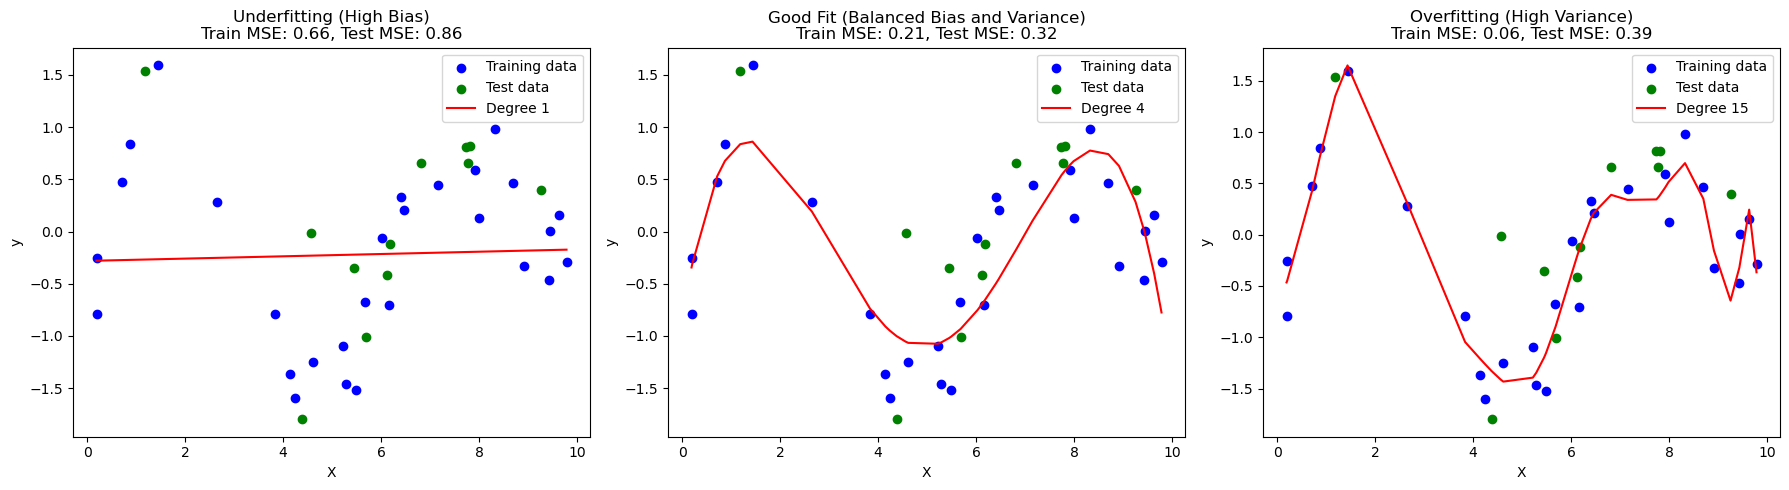

In [1]:
# for demonstration purposes only ignore the code
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Generate synthetic data
np.random.seed(0)
dummy_X = np.sort(np.random.rand(40, 1) * 10, axis=0)
dummy_y = np.sin(dummy_X).ravel() + np.random.randn(40) * 0.5

# Split data into training and test sets
dummy_X_train, dummy_X_test, dummy_y_train, dummy_y_test = train_test_split(dummy_X, dummy_y, test_size=0.3, random_state=0)

# Function to plot model predictions
def plot_model(degree, title, ax):
    polynomial_features = PolynomialFeatures(degree=degree)
    X_poly_train = polynomial_features.fit_transform(dummy_X_train)
    X_poly_test = polynomial_features.transform(dummy_X_test)
    
    model = LinearRegression()
    model.fit(X_poly_train, dummy_y_train)
    
    y_train_pred = model.predict(X_poly_train)
    y_test_pred = model.predict(X_poly_test)
    
    ax.scatter(dummy_X_train, dummy_y_train, color='blue', label='Training data')
    ax.scatter(dummy_X_test, dummy_y_test, color='green', label='Test data')
    ax.plot(dummy_X, model.predict(polynomial_features.transform(dummy_X)), color='red', label=f'Degree {degree}')
    ax.set_xlabel('X')
    ax.set_ylabel('y')
    ax.legend()
    ax.set_title(f'{title}\nTrain MSE: {mean_squared_error(dummy_y_train, y_train_pred):.2f}, Test MSE: {mean_squared_error(dummy_y_test, y_test_pred):.2f}')

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot models with different degrees and titles
plot_model(1, 'Underfitting (High Bias)', axes[0])
plot_model(4, 'Good Fit (Balanced Bias and Variance)', axes[1])
plot_model(15, 'Overfitting (High Variance)', axes[2])

plt.tight_layout()
plt.show()

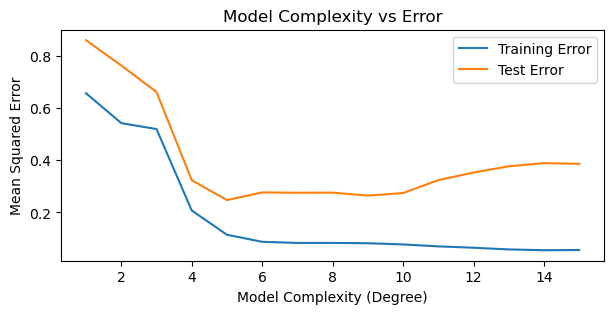

In [19]:
# Plot model complexity vs error
degrees = range(1, 16)
train_errors = []
test_errors = []

for degree in degrees:
    polynomial_features = PolynomialFeatures(degree=degree)
    X_poly_train = polynomial_features.fit_transform(dummy_X_train)
    X_poly_test = polynomial_features.transform(dummy_X_test)
    
    model = LinearRegression()
    model.fit(X_poly_train, dummy_y_train)
    
    y_train_pred = model.predict(X_poly_train)
    y_test_pred = model.predict(X_poly_test)
    
    train_errors.append(mean_squared_error(dummy_y_train, y_train_pred))
    test_errors.append(mean_squared_error(dummy_y_test, y_test_pred))

plt.figure(figsize=(7, 3))
plt.plot(degrees, train_errors, label='Training Error')
plt.plot(degrees, test_errors, label='Test Error')
plt.xlabel('Model Complexity (Degree)')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.title('Model Complexity vs Error')
plt.show()

### Interpreting Training and Validation Errors

| Pattern | Possible explanation | What to investigate |
| --- | --- | --- |
| Low training error, higher validation error | Overfitting or a distribution difference | Representativeness, flexibility, regularisation |
| Both errors high for the application | Underfitting, weak features or substantial noise | Features, assumptions, achievable error |
| Results vary strongly across splits | Unstable estimates or heterogeneous data | Sample size and grouped/temporal splitting |
| Unexpectedly near-perfect validation performance | Possibly leakage or an easy task | Target-related inputs and evaluation protocol |

### What Is on the Horizontal Axis?

- **Training-set size:** refit a fresh model using progressively more observations. A persistent train/validation gap can suggest variance; similarly high errors can suggest limited capacity or substantial noise. Individual curves need not be monotonic.
- **Optimisation steps or epochs:** keep the training set fixed and follow the fitting algorithm. Falling training loss with rising validation loss can motivate early stopping.

The next plots vary **sample count**, not epochs. They use one fixed validation set and one shuffled ordering of training rows. A plateau does not prove optimisation convergence, and similar errors alone do not establish fitness for the application.

At a fixed Ridge alpha, the coefficient penalty becomes weaker relative to its summed squared-error term as the training sample grows. These curves describe each estimator at its stated fixed settings.

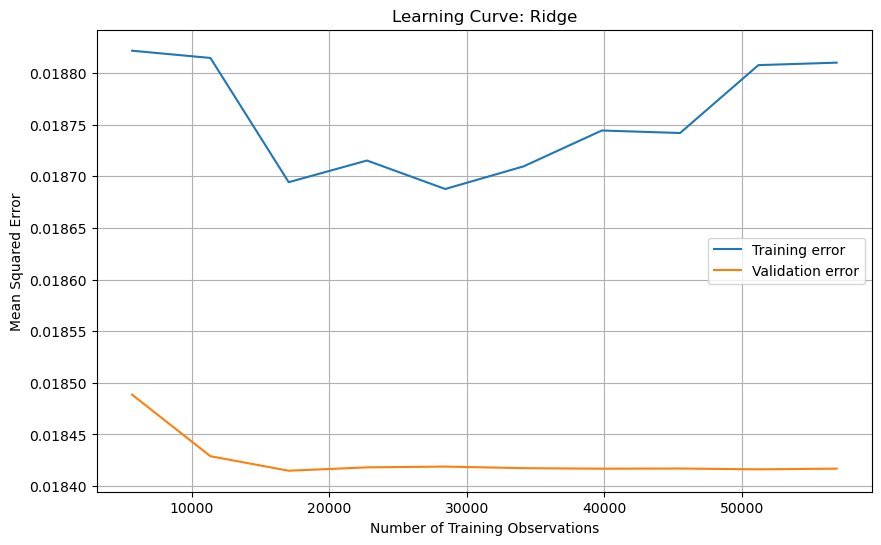

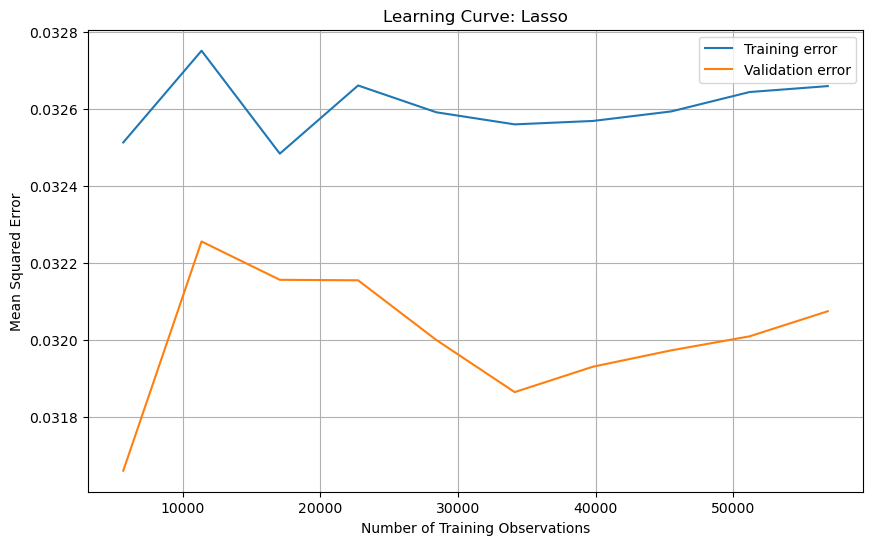

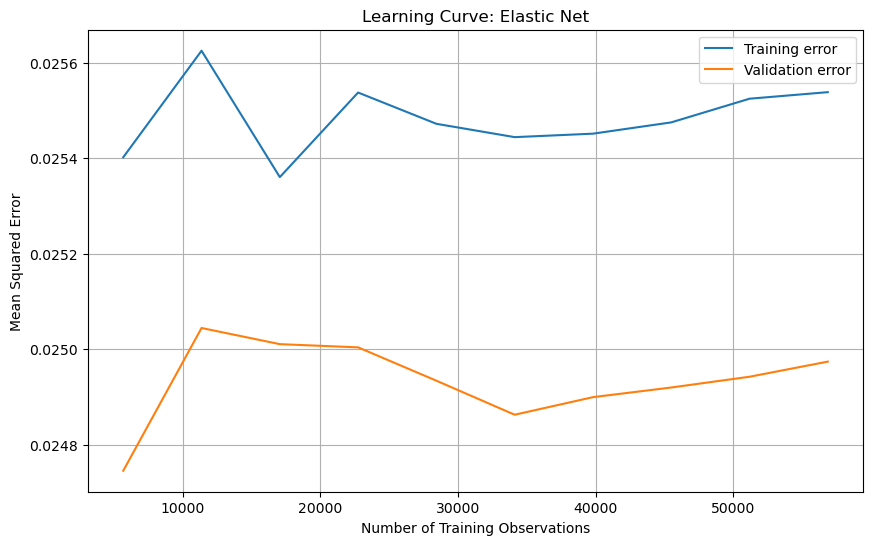

In [20]:
from sklearn.base import clone

def plot_learning_curve_simple(estimator, X_train, y_train, X_val, y_val, title):
    train_errors = []
    val_errors = []
    train_sizes = np.unique(np.linspace(0.1 * len(X_train), len(X_train), 10).astype(int))
    for n in train_sizes:
        X_subset, y_subset = X_train.iloc[:n], y_train.iloc[:n]
        # Learn every preprocessing step using this subset only.
        subset_imputer = SimpleImputer(strategy='median')
        train_imp = pd.DataFrame(subset_imputer.fit_transform(X_subset), columns=X_subset.columns)
        val_imp = pd.DataFrame(subset_imputer.transform(X_val), columns=X_subset.columns)
        lower, upper = iqr_caps(train_imp)
        train_capped = winsorize(train_imp, lower, upper)
        val_capped = winsorize(val_imp, lower, upper)
        subset_scaler = StandardScaler()
        train_scaled = subset_scaler.fit_transform(train_capped)
        val_scaled = subset_scaler.transform(val_capped)
        subset_model = clone(estimator)
        subset_model.fit(train_scaled, y_subset)
        train_errors.append(mean_squared_error(y_subset, subset_model.predict(train_scaled)))
        val_errors.append(mean_squared_error(y_val, subset_model.predict(val_scaled)))

    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_errors, label='Training error')
    plt.plot(train_sizes, val_errors, label='Validation error')
    plt.xlabel('Number of Training Observations')
    plt.ylabel('Mean Squared Error')
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()
    return train_sizes, train_errors, val_errors

learning_curves = {}
for name, estimator in models.items():
    learning_curves[name] = plot_learning_curve_simple(
        estimator, X_train, y_train, X_val, y_val, 'Learning Curve: ' + name
    )

## How to mitigate overfitting and underfitting
#### To Mitigate Overfitting:

- **Regularization**: Techniques like Ridge (L2) and Lasso (L1) can help control the complexity of the model by penalizing large coefficients.
- **Pruning**: For decision trees, pruning can reduce model complexity and help prevent overfittin.##

## To Mitigate Underfitting:

- **Increase Model Complexity**: Use a more complex model, such as moving from linear to polynomial regression or adding more features.
- **Feature Engineering**: Create new features that capture additional patterns in the data.
- **Reduce Regularization**: If regularization is too strong, reduce it to allow the model to capture more of the underlying patterns.
atterns.


# FAQ:

<div style="background-color:rgba(75, 0, 130, 0.3); padding:10px;">

**1. How do I decide what is an outlier?**

Box plots and statistics flag unusual observations. Domain knowledge helps distinguish errors from rare but valid cases. A very large earthquake may be rare yet central to a hazard application. Do not remove legitimate extremes merely to improve a score. The appropriate loss, model and evaluation population depend on the purpose.

---

**2. Can I choose the loss, regularisation and learning rate?**

`SGDRegressor` provides these choices:
- **Loss:** `squared_error` for squared-error regression, or `huber` for reduced sensitivity to large residuals.
- **Penalty:** L1, L2 or Elastic Net.
- **Learning rate:** a step-size schedule for stochastic gradient descent.

Scale features appropriately and check convergence. Changing the optimiser's settings is different from changing regularisation strength.

---

**3. When should I choose OLS, Ridge, Lasso or Elastic Net?**

- **OLS:** an unregularised baseline; coefficients can be unstable with correlated predictors.
- **Ridge:** shrinkage can stabilise estimates. It does not generally enforce exact zeros.
- **Lasso:** useful for sparse coefficients; correlated predictors can make the allocation or selected subset unstable.
- **Elastic Net:** combines L1 and L2 penalties, with a mixing parameter as well as an overall strength.

Compare suitable settings using validation data. Coefficient penalties depend on feature units; equal alpha values across these estimators need not mean equal penalty strength.

**4. What is the difference between validation and verification?**

See `computational-mathematics/lectures/lecture04/errors-verification-validation.ipynb`.

**5. What if training error decreases while validation error stays flat?**

First identify the horizontal axis. With optimisation steps, fitting is improving training loss without a corresponding validation improvement. With training-set size, the pattern alone does not identify underfitting or overfitting. Examine error levels, the gap, sampling variation and the application tolerance.

**6. Plot Ridge coefficients as a function of regularisation.**

The example below shows a fixed design and different alpha values.

</div>

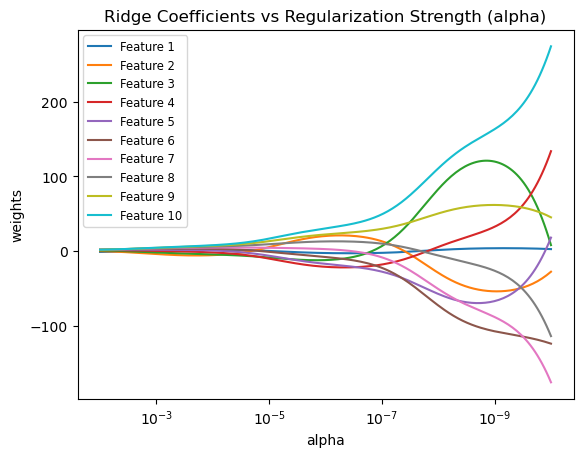

In [21]:
# Akcnowledge: Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import matplotlib.pyplot as plt
import numpy as np

from sklearn import linear_model

# X is the 10x10 Hilbert matrix
X = 1.0 / (np.arange(1, 11) + np.arange(0, 10)[:, np.newaxis])
y = np.ones(10)
n_alphas = 200
alphas = np.logspace(-10, -2, n_alphas)

coefs = []
for a in alphas:
    ridge = linear_model.Ridge(alpha=a, fit_intercept=False)
    ridge.fit(X, y)
    coefs.append(ridge.coef_)
ax = plt.gca()

ax.plot(alphas, coefs)
ax.set_xscale("log")
ax.set_xlim(ax.get_xlim()[::-1])  # reverse axis
plt.xlabel("alpha")
plt.ylabel("weights")
plt.title("Ridge Coefficients vs Regularization Strength (alpha)")
plt.axis("tight")
plt.legend(
    [f"Feature {i + 1}" for i in range(X.shape[1])], loc="best", fontsize="small"
)
plt.show()